# SUNSHIELD v2 — Notebook 2: Window Size & LSTM Training

**Input:** `step1_outputs` (Notebook 1). **Output:** `step2_outputs` (+ `step2_outputs.zip`).

What is the same as before: the window-size experiment (8, 16, 24, 32, 48), the chosen window (48 = 12 h),
the LSTM (64 → 32 units, dropout 0.2), the 3 weather inputs, `TARGET_SHIFT = 0`, seed, epochs, early stopping.

What is new (marked **NEW** below):
1. **Physical expected power** of every reading (NREL PVWatts formula, Dobos 2014). It is used to find the
   readings that are clearly faulty, and in Notebook 3 it is the reference for the *actual* 0/1.
2. **The LSTM is trained on healthy readings only** (normal-behaviour model, as in Malhotra et al. 2015 and
   the normal-behaviour-modelling review of Chesterman et al. 2023). Faulty readings are removed from the
   training and validation targets; the weather windows themselves are not changed.
3. **Experiment:** the same LSTM is also trained on *all* readings (faults included, exactly as in the previous
   version), so Notebook 4 can show which training gives the higher F1.

## Inputs (works on Colab and locally)

In [1]:
import os, shutil, zipfile

def find_root():
    for d in ['.', '..', '../..']:
        if os.path.exists(os.path.join(d, 'data', 'raw', 'Plant_1_Generation_Data.csv')):
            return os.path.abspath(d)
    return os.path.abspath('.')          # Colab: /content

ROOT = find_root()
OUTPUTS = os.path.join(ROOT, 'outputs')

def get_step(name):
    """Folder of a previous notebook's outputs; on Colab, asks for its zip file if the folder is missing."""
    folder = os.path.join(OUTPUTS, name)
    if not os.path.isdir(folder):
        zip_path = os.path.join(OUTPUTS, name + '.zip') if os.path.exists(os.path.join(OUTPUTS, name + '.zip')) else name + '.zip'
        if not os.path.exists(zip_path):
            from google.colab import files
            print(f'Upload {name}.zip'); uploaded = files.upload(); zip_path = list(uploaded)[0]
        shutil.unpack_archive(zip_path, folder, 'zip')
    return folder

STEP1_DIR = get_step('step1_outputs')
OUT_DIR = os.path.join(OUTPUTS, 'step2_outputs')
os.makedirs(OUT_DIR, exist_ok=True)
print('Inputs :', STEP1_DIR, sorted(os.listdir(STEP1_DIR)))
print('Outputs:', OUT_DIR)

Inputs : /home/user/SUNSHIELD/outputs/step1_outputs ['clean_data.csv', 'merged_data.csv', 'missing_values.csv', 'row_counts.csv', 'scalers.pkl', 'split_summary.csv', 'windows_per_split.csv']
Outputs: /home/user/SUNSHIELD/outputs/step2_outputs


## Settings

In [2]:
import time, joblib
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

SEED = 42
WINDOW_SIZES = [8, 16, 24, 32, 48]
TARGET_SHIFT = 0             # the window ends at the predicted reading (weather at the same time); same as Notebook 1
EPOCHS = 100
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
PATIENCE = 10
RUN_WINDOW_EXPERIMENT = True # False: skip Step 1 and use the window chosen before (48)

# NEW — physical reference and healthy readings
GAMMA = -0.0047              # power temperature coefficient (1/°C), PVWatts v5 "standard" module (Dobos 2014)
IRR_MIN = 0.2                # kW/m² = 200 W/m²: lower irradiance limit of the RdTools filter (NREL); below it the
                             # expected power is too small and too uncertain to judge a reading
HEALTH_K = 3.0               # a training reading is "healthy" if it is inside median ± 3·σ (classic 3-sigma / Hampel)

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

# Chart style (light surface, recessive grid, 2 px lines)
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE, GREEN = '#2a78d6', '#eb6834', '#2ca02c'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
                     'axes.titlecolor': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'legend.frameon': False, 'font.size': 10})

print('TensorFlow', tf.__version__, '| GPU:', bool(tf.config.list_physical_devices('GPU')))

I0000 00:00:1795093707.018827    6278 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795093708.164373    6278 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: False


## Load Notebook 1 outputs and the window builder (unchanged)

In [3]:
clean = pd.read_csv(os.path.join(STEP1_DIR, 'clean_data.csv'), parse_dates=['DATE_TIME'])
clean = clean.sort_values(['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)
scalers = joblib.load(os.path.join(STEP1_DIR, 'scalers.pkl'))
target_scaler = scalers['target']

FEATURES, TARGET = scalers['feature_names'], scalers['target_name']
FEATURES_Z, TARGET_Z = [c + '_z' for c in FEATURES], TARGET + '_z'
SPLITS = ['train', 'val', 'test']
KW_PER_Z = target_scaler.scale_[0]      # 1 scaled unit of AC_POWER = this many kW

def build_windows(df, window, target_shift=TARGET_SHIFT, features=FEATURES_Z, target=TARGET_Z):
    '''Returns {split: (X, y, meta)}.
    X: (n, window, n_features) scaled inputs, y: (n,) scaled AC_POWER,
    meta: PLANT_ID, SOURCE_KEY, DATE_TIME and AC_POWER (kW) of each target reading.
    df must be sorted by inverter and time and have RUN_ID and SPLIT columns.'''
    X_parts, target_rows = [], []
    feats = df[features].to_numpy(np.float32)
    for rows in df.groupby('RUN_ID', sort=False).indices.values():
        n_win = len(rows) - window - target_shift + 1
        if n_win <= 0:
            continue
        w = np.lib.stride_tricks.sliding_window_view(feats[rows], window, axis=0)[:n_win]
        X_parts.append(w.transpose(0, 2, 1))
        target_rows.append(rows[window - 1 + target_shift:])
    X = np.concatenate(X_parts)
    t = np.concatenate(target_rows)
    y = df[target].to_numpy(np.float32)[t]
    meta = df.iloc[t][['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME', TARGET, 'SPLIT']].reset_index(drop=True)
    return {s: (X[(meta['SPLIT'] == s).to_numpy()], y[(meta['SPLIT'] == s).to_numpy()],
                meta[meta['SPLIT'] == s].drop(columns='SPLIT').reset_index(drop=True))
            for s in SPLITS}

print(f'{len(clean):,} rows | 1 scaled unit of {TARGET} = {KW_PER_Z:.1f} kW')
clean.groupby('SPLIT').size().loc[SPLITS]

77,102 rows | 1 scaled unit of AC_POWER = 405.0 kW


SPLIT
train    53342
val      11968
test     11792
dtype: int64

## The model and the training (unchanged)

In [4]:
def build_lstm(window, n_features=len(FEATURES)):
    model = keras.Sequential([
        keras.Input(shape=(window, n_features)),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.2),
        layers.LSTM(32),
        layers.Dropout(0.2),
        layers.Dense(1),
    ], name=f'lstm_window_{window}')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss='mse')
    return model

def fit_model(model, data, extra_callbacks=(), verbose=2):
    X_tr, y_tr, _ = data['train']
    X_va, y_va, _ = data['val']
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                               restore_best_weights=True)
    return model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                     epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True,
                     callbacks=[early_stop, *extra_callbacks], verbose=verbose)

## Step 1 — Window-size experiment (8, 16, 24, 32, 48) with the same settings and seed (unchanged)

In [5]:
if RUN_WINDOW_EXPERIMENT:
    experiment, n_val_targets = [], set()
    for W in WINDOW_SIZES:
        print(f'=== Window size {W} ({W * 15 / 60:g} hours) ===')
        data = build_windows(clean, W)
        n_val_targets.add(len(data['val'][1]))
        keras.utils.set_random_seed(SEED)
        start = time.time()
        history = fit_model(build_lstm(W), data, verbose=0).history
        best_epoch = int(np.argmin(history['val_loss']))
        experiment.append({
            'window size': W,
            'hours': W * 15 / 60,
            'train windows': len(data['train'][1]),
            'epochs run': len(history['val_loss']),
            'best epoch': best_epoch + 1,
            'train loss (MSE, scaled)': history['loss'][best_epoch],
            'val loss (MSE, scaled)': history['val_loss'][best_epoch],
            'val RMSE (kW)': np.sqrt(history['val_loss'][best_epoch]) * KW_PER_Z,
            'minutes': (time.time() - start) / 60,
        })
    assert len(n_val_targets) == 1, 'window sizes are not evaluated on the same validation readings'
    experiment = pd.DataFrame(experiment).set_index('window size')
    experiment.to_csv(os.path.join(OUT_DIR, 'window_size_experiment.csv'))
    display(experiment.round(4))

=== Window size 8 (2 hours) ===


=== Window size 16 (4 hours) ===


=== Window size 24 (6 hours) ===


=== Window size 32 (8 hours) ===


=== Window size 48 (12 hours) ===


,hours,train windows,epochs run,best epoch,"train loss (MSE, scaled)","val loss (MSE, scaled)",val RMSE (kW),minutes
window size,,,,,,,,
8,2.0,50619,17,7,0.3171,0.1922,177.5660,0.9629
16,4.0,47659,20,10,0.3217,0.1949,178.8057,1.6473
24,6.0,44753,16,6,0.3381,0.1952,178.9430,1.8377
32,8.0,41937,21,11,0.3359,0.1914,177.2004,2.7742
48,12.0,36491,20,10,0.3391,0.1913,177.1610,3.2537


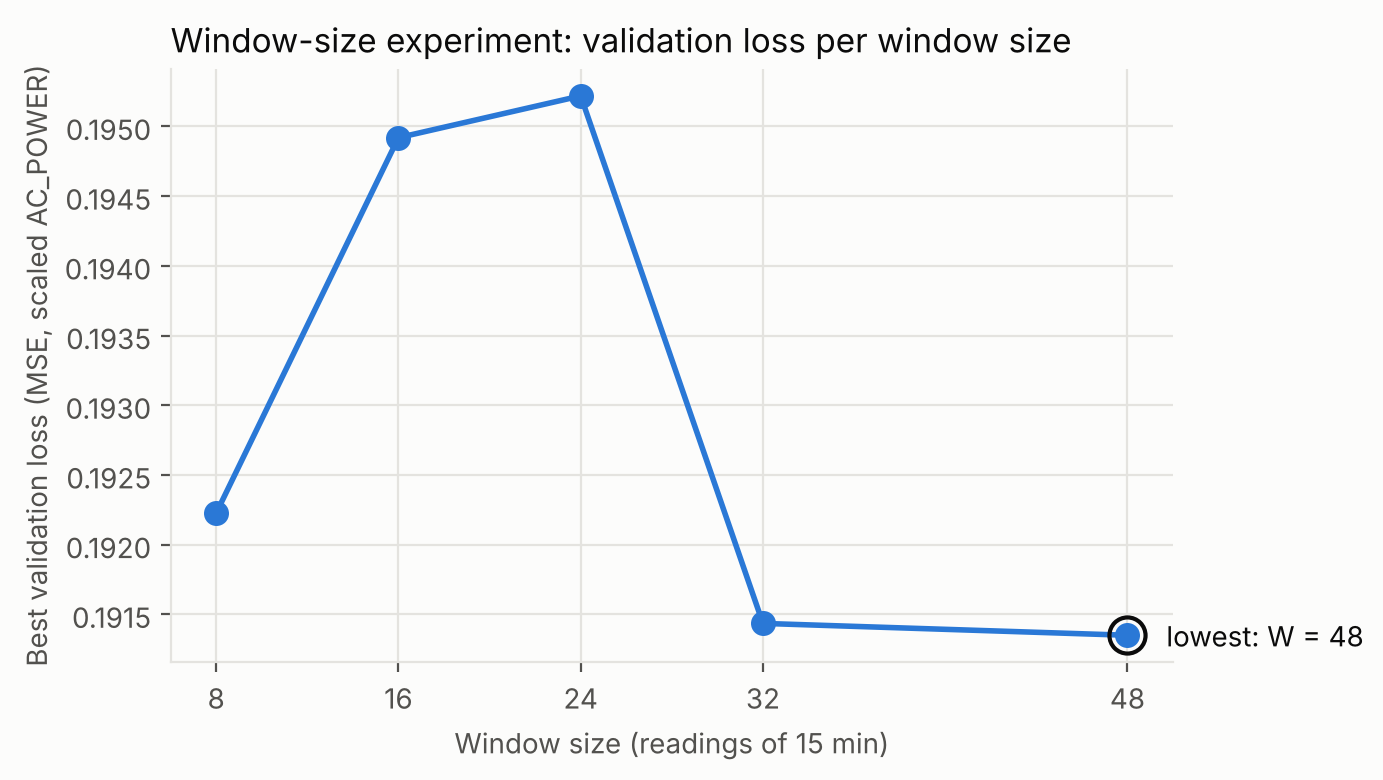

In [6]:
if RUN_WINDOW_EXPERIMENT:
    best_W = int(experiment['val loss (MSE, scaled)'].idxmin())
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(experiment.index, experiment['val loss (MSE, scaled)'], color=BLUE, marker='o', markersize=8)
    ax.plot(best_W, experiment.loc[best_W, 'val loss (MSE, scaled)'], 'o', markersize=13,
            markerfacecolor='none', markeredgecolor=INK, markeredgewidth=1.5)
    ax.annotate(f'lowest: W = {best_W}', (best_W, experiment.loc[best_W, 'val loss (MSE, scaled)']),
                textcoords='offset points', xytext=(14, -4), ha='left', color=INK)
    ax.set_xticks(WINDOW_SIZES)
    ax.set_xlabel('Window size (readings of 15 min)')
    ax.set_ylabel('Best validation loss (MSE, scaled AC_POWER)')
    ax.set_title('Window-size experiment: validation loss per window size', loc='left')
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, 'window_size_experiment.png'), dpi=150)
    plt.show()
else:
    best_W = 48
    print('Window experiment skipped; using the window chosen before: W = 48')

## Step 2 — Choose the window by validation loss (unchanged)

In [7]:
if RUN_WINDOW_EXPERIMENT:
    second_W = int(experiment['val loss (MSE, scaled)'].drop(best_W).idxmin())
    gap_pct = 100 * (experiment.loc[second_W, 'val loss (MSE, scaled)'] / experiment.loc[best_W, 'val loss (MSE, scaled)'] - 1)
    justification = (
        f'Window size {best_W} ({best_W * 15 / 60:g} h) was selected because it gave the lowest '
        f'validation loss (MSE {experiment.loc[best_W, "val loss (MSE, scaled)"]:.4f}, RMSE '
        f'{experiment.loc[best_W, "val RMSE (kW)"]:.1f} kW) among {WINDOW_SIZES}. '
        f'It is only {gap_pct:.2f}% lower than the next best (W = {second_W}), so the two are practically tied.')
else:
    justification = 'Window size 48 (12 h), chosen by the window-size experiment of the previous version.'
with open(os.path.join(OUT_DIR, 'window_justification.txt'), 'w') as f:
    f.write(justification + '\n')
print(justification)

Window size 48 (12 h) was selected because it gave the lowest validation loss (MSE 0.1913, RMSE 177.2 kW) among [8, 16, 24, 32, 48]. It is only 0.04% lower than the next best (W = 32), so the two are practically tied.


## Step 3 — NEW: physical expected power (PVWatts) and the healthy readings

**Expected power from physics** (PVWatts DC model, NREL — Dobos 2014):

$$P_{expected} = P_{ref} \cdot G \cdot \big(1 + \gamma\,(T_{module} - 25\,°C)\big)$$

- $G$ = `IRRADIATION` (kW/m²), $T_{module}$ = `MODULE_TEMPERATURE` (measured), $\gamma = -0.0047$ /°C.
- $P_{ref}$ = AC power of the inverter at 1 kW/m² and 25 °C. It is not on the data sheet, so it is taken from the
  **training days only**: median of `AC_POWER / (G · temperature factor)` over readings with $G \ge 0.2$ kW/m².
  The median is not pulled down by the outages (Leys et al. 2013).

**Healthy reading** = its deviation from the physical expected power is normal:
residual $r = AC - P_{expected}$; for each inverter $\mu$ = median and $\sigma = 1.4826 \cdot MAD$ of $r$ on the
training readings with $G \ge 0.2$; healthy if $|r - \mu| \le 3\sigma$.

We also keep the **median AC power of the other inverters of the same plant at the same moment** (peers).
It is not used by the method; Notebook 4 uses it for an independent check of the outages.

In [8]:
clean['TEMP_FACTOR'] = 1 + GAMMA * (clean['MODULE_TEMPERATURE'] - 25)
calib = clean[(clean['SPLIT'] == 'train') & (clean['IRRADIATION'] >= IRR_MIN)]
P_REF = (calib['AC_POWER'] / (calib['IRRADIATION'] * calib['TEMP_FACTOR'])).groupby(calib['SOURCE_KEY']).median()
clean['EXPECTED_PHYS_kW'] = clean['SOURCE_KEY'].map(P_REF) * clean['IRRADIATION'] * clean['TEMP_FACTOR']

def robust_mu_sigma(x):
    '''Median and 1.4826 * MAD: the mean and std of normal data, but not pulled by faults (Leys et al. 2013).'''
    x = np.asarray(x, float)
    med = np.median(x)
    return med, 1.4826 * np.median(np.abs(x - med))

r = clean['AC_POWER'] - clean['EXPECTED_PHYS_kW']
ref_rows = (clean['SPLIT'] == 'train') & (clean['IRRADIATION'] >= IRR_MIN)
health_stats = pd.DataFrame({inv: robust_mu_sigma(g) for inv, g in r[ref_rows].groupby(clean.loc[ref_rows, 'SOURCE_KEY'])},
                            index=['mu', 'sigma']).T
mu, sigma = clean['SOURCE_KEY'].map(health_stats['mu']), clean['SOURCE_KEY'].map(health_stats['sigma'])
clean['HEALTHY'] = (r - mu).abs() <= HEALTH_K * sigma

# Peers: median of the OTHER inverters of the same plant at the same time (only for the check in Notebook 4)
def median_of_others(v):
    v = np.asarray(v, float)
    return np.array([np.median(np.delete(v, i)) if len(v) > 1 else np.nan for i in range(len(v))])
clean['PEER_MEDIAN_kW'] = clean.groupby(['PLANT_ID', 'DATE_TIME'])['AC_POWER'].transform(median_of_others)

print('P_ref per inverter (kW at 1 kW/m², 25 °C): '
      f'plant 1 median {P_REF[clean.loc[clean.PLANT_ID == 4135001, "SOURCE_KEY"].unique()].median():.0f}, '
      f'plant 2 median {P_REF[clean.loc[clean.PLANT_ID == 4136001, "SOURCE_KEY"].unique()].median():.0f}')
outage = (clean['AC_POWER'] == 0) & (clean['IRRADIATION'] >= IRR_MIN)
print(f'Readings with AC_POWER = 0 while irradiation >= {IRR_MIN}: {outage.sum():,} '
      f'-> marked healthy: {(outage & clean["HEALTHY"]).sum()}')
share = clean.groupby(['PLANT_ID', 'SPLIT'])['HEALTHY'].agg(['size', 'sum', 'mean']).rename(
    columns={'size': 'readings', 'sum': 'healthy', 'mean': 'healthy share'})
share['removed'] = share['readings'] - share['healthy']
share.round(3)

P_ref per inverter (kW at 1 kW/m², 25 °C): plant 1 median 1499, plant 2 median 1502
Readings with AC_POWER = 0 while irradiation >= 0.2: 3,821 -> marked healthy: 4


readings  healthy  healthy share  removed
PLANT_ID SPLIT                                           
4135001  test       5786     5640          0.975      146
         train     26808    25652          0.957     1156
         val        5786     5671          0.980      115
4136001  test       6006     5299          0.882      707
         train     26534    22915          0.864     3619
         val        6182     5444          0.881      738

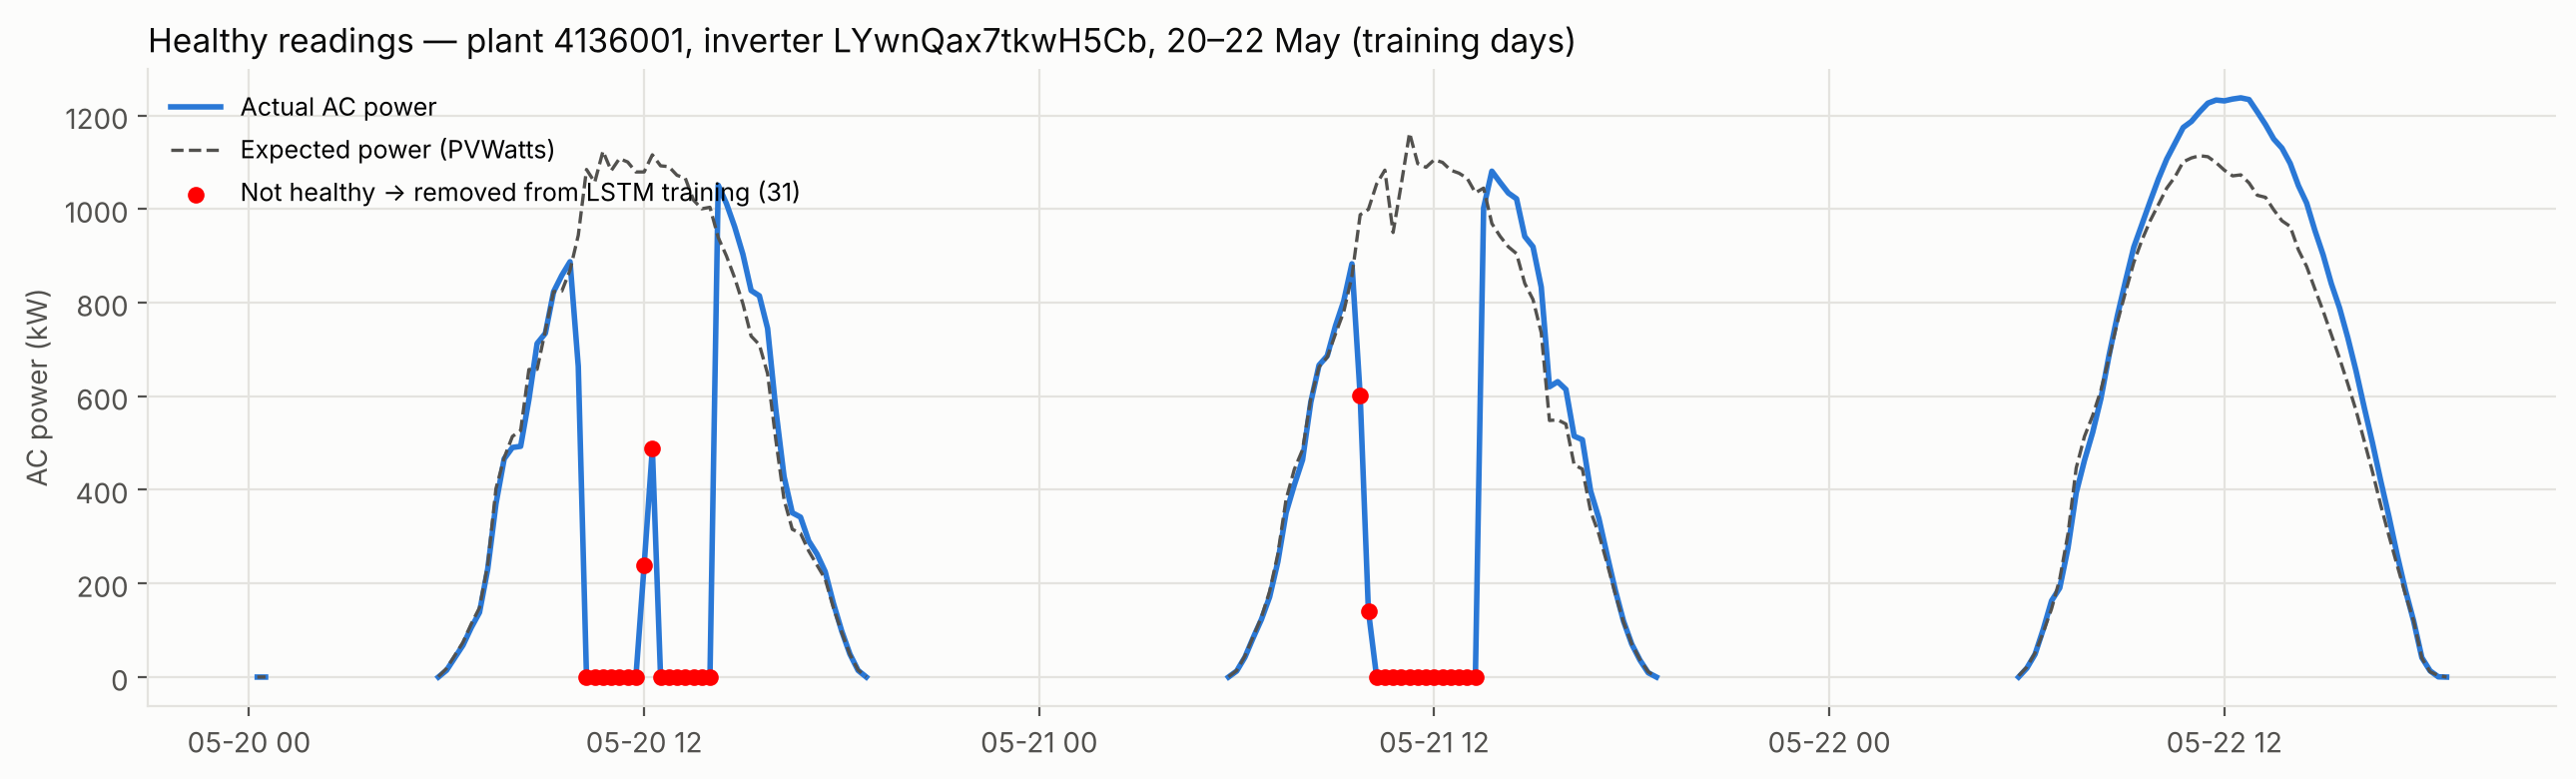

In [9]:
# Picture of the physical check: one plant-2 inverter with outages (training days)
inv = clean.loc[clean['PLANT_ID'] == 4136001].assign(o=outage).groupby('SOURCE_KEY')['o'].sum().idxmax()
d = clean[(clean['SOURCE_KEY'] == inv) & (clean['DATE_TIME'] >= '2020-05-20') & (clean['DATE_TIME'] < '2020-05-23')]
d = d.set_index('DATE_TIME').reindex(pd.date_range('2020-05-20', '2020-05-23', freq='15min', inclusive='left'))
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(d.index, d['AC_POWER'], color=BLUE, label='Actual AC power')
ax.plot(d.index, d['EXPECTED_PHYS_kW'], color=INK_2, linewidth=1.2, linestyle='--', label='Expected power (PVWatts)')
bad = d[d['HEALTHY'] == False]
ax.scatter(bad.index, bad['AC_POWER'], color='red', s=25, zorder=4, label=f'Not healthy → removed from LSTM training ({len(bad)})')
ax.set_title(f'Healthy readings — plant 4136001, inverter {inv}, 20–22 May (training days)', loc='left')
ax.set_ylabel('AC power (kW)'); ax.legend(loc='upper left', fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'healthy_readings_example.png'), dpi=150); plt.show()

## Step 4 — Build the LSTM with the chosen window (unchanged)

In [10]:
keras.utils.set_random_seed(SEED)
model = build_lstm(best_W)
model.summary()
with open(os.path.join(OUT_DIR, 'model_summary.txt'), 'w') as f:
    model.summary(print_fn=lambda line, **kwargs: f.write(line + '\n'))

Model: "lstm_window_48"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 48, 64)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

## Step 5 — NEW: train on HEALTHY readings only (normal behaviour); validation = healthy readings, for early stopping

The windows are built exactly as before from all readings (so every reading still gets a prediction later);
only the training and validation **targets** that are not healthy are left out of `fit`.

In [11]:
data_all = build_windows(clean, best_W)
health = clean[['SOURCE_KEY', 'DATE_TIME', 'HEALTHY']]
data_healthy = {}
for s in SPLITS:
    X, y, meta = data_all[s]
    ok = meta[['SOURCE_KEY', 'DATE_TIME']].merge(health, on=['SOURCE_KEY', 'DATE_TIME'], how='left')['HEALTHY'].to_numpy(bool)
    data_healthy[s] = (X[ok], y[ok], meta[ok].reset_index(drop=True))
    print(f'{s:5s}: {len(y):,} windows -> {ok.sum():,} healthy targets ({len(y) - ok.sum():,} left out)')

keras.utils.set_random_seed(SEED)
model = build_lstm(best_W)
history_healthy = fit_model(model, data_healthy, [keras.callbacks.CSVLogger(os.path.join(OUT_DIR, 'training_log.csv'))]).history
model.save(os.path.join(OUT_DIR, 'lstm_model.keras'))
best_epoch_h = int(np.argmin(history_healthy['val_loss']))
print(f'Healthy model: {len(history_healthy["val_loss"])} epochs, best epoch {best_epoch_h + 1} '
      f'(val loss {history_healthy["val_loss"][best_epoch_h]:.4f})')

train: 36,491 windows -> 32,882 healthy targets (3,609 left out)
val  : 11,968 windows -> 11,115 healthy targets (853 left out)
test : 10,758 windows -> 9,911 healthy targets (847 left out)
Epoch 1/100


129/129 - 10s - 74ms/step - loss: 0.1907 - val_loss: 0.0788


Epoch 2/100


129/129 - 8s - 62ms/step - loss: 0.0853 - val_loss: 0.0263


Epoch 3/100


129/129 - 8s - 65ms/step - loss: 0.0412 - val_loss: 0.0155


... (37 outputs left out)

129/129 - 7s - 57ms/step - loss: 0.0236 - val_loss: 0.0121


Epoch 23/100


129/129 - 8s - 65ms/step - loss: 0.0236 - val_loss: 0.0120


Healthy model: 23 epochs, best epoch 13 (val loss 0.0117)


## Step 6 — EXPERIMENT: the same LSTM trained on ALL readings (faults included), as in the previous version

In [12]:
keras.utils.set_random_seed(SEED)
model_all = build_lstm(best_W)
history_all = fit_model(model_all, data_all, [keras.callbacks.CSVLogger(os.path.join(OUT_DIR, 'training_log_all_data.csv'))]).history
model_all.save(os.path.join(OUT_DIR, 'lstm_model_all_data.keras'))
best_epoch_a = int(np.argmin(history_all['val_loss']))
print(f'All-data model: {len(history_all["val_loss"])} epochs, best epoch {best_epoch_a + 1} '
      f'(val loss {history_all["val_loss"][best_epoch_a]:.4f})')

Epoch 1/100


143/143 - 11s - 77ms/step - loss: 0.4850 - val_loss: 0.2691


Epoch 2/100


143/143 - 10s - 69ms/step - loss: 0.4209 - val_loss: 0.2235


Epoch 3/100


143/143 - 11s - 74ms/step - loss: 0.3766 - val_loss: 0.1999


... (31 outputs left out)

143/143 - 10s - 73ms/step - loss: 0.3293 - val_loss: 0.2002


Epoch 20/100


143/143 - 11s - 74ms/step - loss: 0.3289 - val_loss: 0.2024


All-data model: 20 epochs, best epoch 10 (val loss 0.1913)


## Step 7 — Training vs validation loss, best epoch marked (both models)

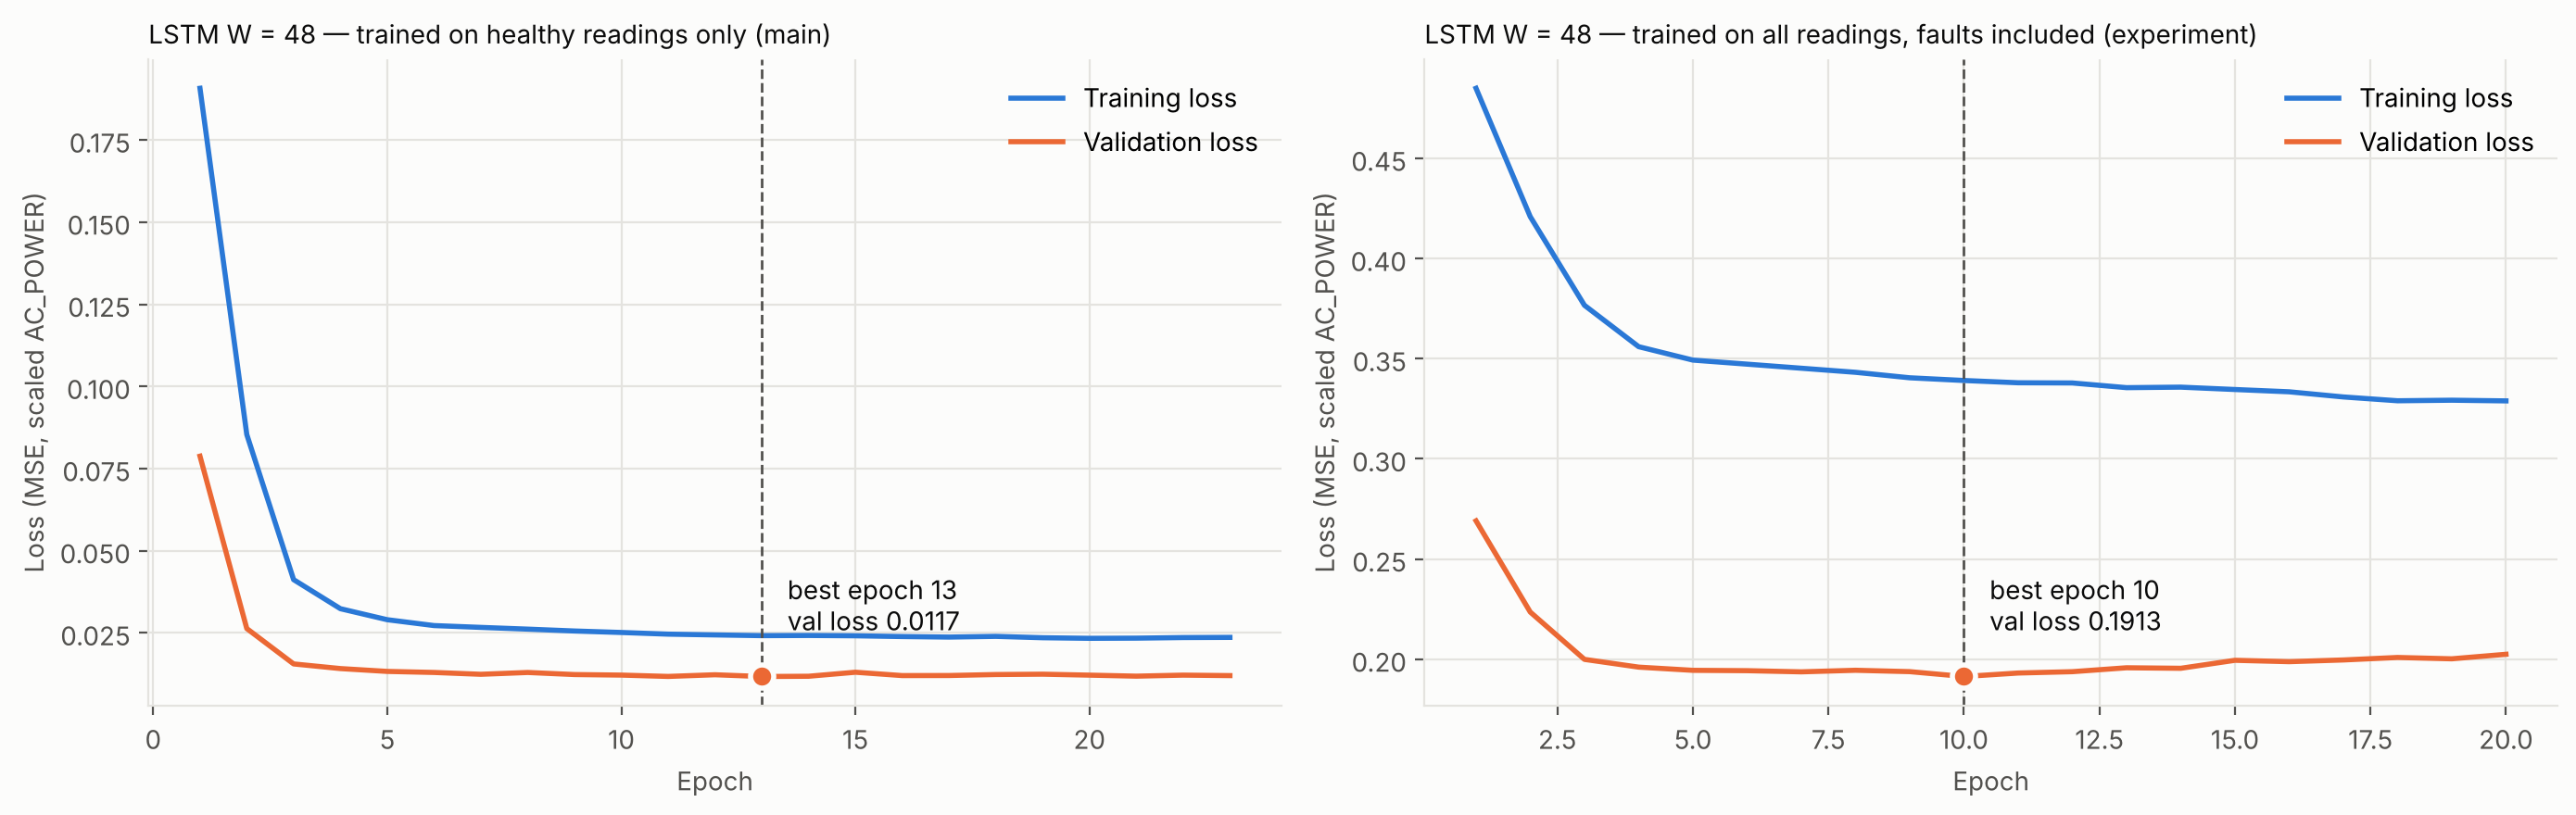

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (name, h, b) in zip(axes, [('healthy readings only (main)', history_healthy, best_epoch_h),
                                   ('all readings, faults included (experiment)', history_all, best_epoch_a)]):
    ep = np.arange(1, len(h['loss']) + 1)
    ax.plot(ep, h['loss'], color=BLUE, label='Training loss')
    ax.plot(ep, h['val_loss'], color=ORANGE, label='Validation loss')
    ax.axvline(b + 1, color=INK_2, linestyle='--', linewidth=1)
    ax.plot(b + 1, h['val_loss'][b], 'o', color=ORANGE, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f'best epoch {b + 1}\nval loss {h["val_loss"][b]:.4f}', (b + 1, h['val_loss'][b]),
                textcoords='offset points', xytext=(10, 18), color=INK)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss (MSE, scaled AC_POWER)')
    ax.set_title(f'LSTM W = {best_W} — trained on {name}', loc='left', fontsize=10)
    ax.legend(loc='upper right')
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'loss_curve.png'), dpi=150); plt.show()

## Step 8 — Predict `AC_POWER` for train / validation / test (both models) and convert back to kW

Negative predictions are set to 0 kW (an inverter cannot produce negative power; option listed in the previous report).
Each file has one row per reading with the actual value, both predicted lines, the physical expected power,
the peers' median, the weather and the healthy flag.

In [14]:
extra = clean[['SOURCE_KEY', 'DATE_TIME', 'IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE',
               'EXPECTED_PHYS_kW', 'PEER_MEDIAN_kW', 'HEALTHY']]
predictions = {}
for split in SPLITS:
    X, y, meta = data_all[split]
    out = meta.rename(columns={TARGET: 'ACTUAL_AC_POWER_kW'})
    for col, m in [('PREDICTED_AC_POWER_kW', model), ('PREDICTED_ALL_DATA_kW', model_all)]:
        pred = target_scaler.inverse_transform(m.predict(X, batch_size=2048, verbose=0).reshape(-1, 1)).ravel()
        if col == 'PREDICTED_AC_POWER_kW':
            n_neg = int((pred < 0).sum())
        else:
            out['PREDICTED_ALL_DATA_RAW_kW'] = pred      # unclipped, only to recompute the previous rules exactly
        out[col] = np.clip(pred, 0, None)
    out = out.merge(extra, on=['SOURCE_KEY', 'DATE_TIME'], how='left')
    out = out.sort_values(['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)
    out.to_csv(os.path.join(OUT_DIR, f'prediction_{split}.csv'), index=False)
    predictions[split] = out
    print(f'{split:5s}: {len(out):,} predictions | negative predictions set to 0: {n_neg}')
predictions['test'].head()

train: 36,491 predictions | negative predictions set to 0: 1658


val  : 11,968 predictions | negative predictions set to 0: 440


test : 10,758 predictions | negative predictions set to 0: 286


,PLANT_ID,SOURCE_KEY,DATE_TIME,ACTUAL_AC_POWER_kW,PREDICTED_AC_POWER_kW,PREDICTED_ALL_DATA_RAW_kW,PREDICTED_ALL_DATA_kW,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,EXPECTED_PHYS_kW,PEER_MEDIAN_kW,HEALTHY
0,4135001,1BY6WEcLGh8j5v7,2020-06-13 05:45:00,0.000000,0.000000,-3.514709,0.000000,0.000152,21.320007,18.526363,0.217613,0.000000,True
1,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:00:00,9.162500,5.545959,13.575562,13.575562,0.008357,21.285130,18.491780,12.002231,8.900000,True
2,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:15:00,33.228571,26.300964,38.895020,38.895020,0.026604,21.227468,18.728929,38.168292,34.337500,True
3,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:30:00,55.037500,47.848938,61.439056,61.439056,0.043715,21.149609,19.307527,62.552656,56.657143,True
4,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:45:00,102.142857,86.431122,96.193695,96.193695,0.074974,21.425932,20.319141,106.783803,100.750000,True


## Step 9 — RMSE and MAE (kW): all readings and healthy readings, both models

The error on **healthy** readings shows how well each model learned normal behaviour. The error on all readings
also contains the faults, which a weather-only model cannot (and should not) predict.

In [15]:
def error_metrics(df, col):
    err = df['ACTUAL_AC_POWER_kW'] - df[col]
    value_range = df['ACTUAL_AC_POWER_kW'].max() - df['ACTUAL_AC_POWER_kW'].min()
    rmse = np.sqrt((err ** 2).mean())
    return {'readings': len(df), 'RMSE (kW)': rmse, 'MAE (kW)': err.abs().mean(), 'RMSE % of range': 100 * rmse / value_range}

rows = []
for s in SPLITS:
    for plant, g in [('both', predictions[s])] + list(predictions[s].groupby('PLANT_ID')):
        for model_name, col in [('healthy only (main)', 'PREDICTED_AC_POWER_kW'), ('all readings', 'PREDICTED_ALL_DATA_kW')]:
            for subset, gg in [('all readings', g), ('healthy readings', g[g['HEALTHY']])]:
                rows.append({'split': s, 'plant': plant, 'trained on': model_name, 'scored on': subset, **error_metrics(gg, col)})
metrics = pd.DataFrame(rows)
metrics.to_csv(os.path.join(OUT_DIR, 'metrics.csv'), index=False)
metrics[metrics['plant'] != 'both'].pivot_table(index=['split', 'plant', 'scored on'], columns='trained on',
                                                values='RMSE (kW)').loc[SPLITS].round(1)

trained on                      all readings  healthy only (main)
split plant   scored on                                          
train 4135001 all readings              72.8                 71.3
              healthy readings          47.6                 42.0
      4136001 all readings             298.5                370.0
              healthy readings         205.0                 50.7
val   4135001 all readings              49.6                 46.6
              healthy readings          41.4                 38.0
      4136001 all readings             241.8                302.7
              healthy readings         162.5                 49.1
test  4135001 all readings              86.4                 83.4
              healthy readings          42.0                 37.8
      4136001 all readings             243.6                279.4
              healthy readings         135.8                 43.6

## Step 10 — Save and zip outputs

In [16]:
pd.Series(P_REF, name='P_REF_kW').to_csv(os.path.join(OUT_DIR, 'physical_reference_P_ref.csv'))
health_stats.to_csv(os.path.join(OUT_DIR, 'healthy_filter_thresholds.csv'))
share.to_csv(os.path.join(OUT_DIR, 'healthy_share.csv'))
with open(os.path.join(OUT_DIR, 'settings.txt'), 'w') as f:
    f.write(f'best_W = {best_W}\nGAMMA = {GAMMA}\nIRR_MIN = {IRR_MIN}\nHEALTH_K = {HEALTH_K}\n')

zip_path = shutil.make_archive(OUT_DIR, 'zip', OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print(f'{f:32s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1e6:6.2f} MB')
try:
    from google.colab import files
    files.download(zip_path)        # Notebook 3 needs it
except ImportError:
    print('Saved to', zip_path)

healthy_filter_thresholds.csv      0.00 MB
healthy_readings_example.png       0.15 MB
healthy_share.csv                  0.00 MB
loss_curve.png                     0.14 MB
lstm_model.keras                   0.40 MB
lstm_model_all_data.keras          0.40 MB
metrics.csv                        0.00 MB
model_summary.txt                  0.00 MB
physical_reference_P_ref.csv       0.00 MB
prediction_test.csv                1.89 MB
prediction_train.csv               6.39 MB
prediction_val.csv                 2.09 MB
settings.txt                       0.00 MB
training_log.csv                   0.00 MB
training_log_all_data.csv          0.00 MB
window_justification.txt           0.00 MB
window_size_experiment.csv         0.00 MB
window_size_experiment.png         0.08 MB
Saved to /home/user/SUNSHIELD/outputs/step2_outputs.zip
